# T05 · Réseaux récurrents : RNN, LSTM, GRU — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- Comprendre la boucle temporelle d'un RNN et la rétropropagation dans le temps (BPTT), écrite à la main en numpy
- Voir *pourquoi* les RNN vanissent sur les séquences longues (chaîne de Jacobiens) et comment LSTM/GRU réparent ça
- Traiter de vrais logs d'authentification : fenêtrage, vocabulaire, padding, puis détecter une exfiltration

**Pourquoi c'est fondamental en cyber :**

| Besoin cyber | Outil |
|---|---|
| Séquences d'événements (logs, flux, keystrokes) | RNN : mémoire de l'historique |
| Attaques lentes (low-and-slow, exfiltration) | LSTM : mémoriser sur des dizaines d'étapes |
| Coût d'inférence sur sonde réseau | GRU : 3 matrices au lieu de 4 |
| Logs hétérogènes, vocabulaire ouvert | Fenêtres glissantes + `<UNK>` + padding |

**Prérequis :** T01 (backprop d'un MLP), T02 (vanishing/exploding gradients),
algèbre linéaire de base (produit matriciel, Jacobien).

> **Conseil d'étude :** refaites l'exercice P1 (BPTT) sur papier — l'indexation
> des gradients temporels `t-1 → t` est LA question tombant aux oraux.

In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
# Block 0 — environment & imports (the builder prepends the !pip line for the notebook)
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


## 1 · La boucle temporelle d'un RNN & BPTT

Un RNN « vanilla » partage **les mêmes poids à chaque pas de temps** :

```
h_t = tanh( W_xh·x_t + W_hh·h_{t-1} + b_h )      (état caché)
y_t = W_hy·h_t + b_y                              (sortie, si supervision pas à pas)
```

**BPTT (BackPropagation Through Time)** : on « déplie » le réseau dans le
temps (T copies du même bloc) et on rétropropage du dernier pas vers le
premier. Comme les poids sont partagés, le gradient de `W_hh` **s'accumule
sur tous les pas** :

```
dL/dW_hh = Σ_t  dL/dh_t · ∂h_t/∂h_{t-1} · ∂h_{t-1}/∂W_hh
```

**Piège classique :** confondre *déplier* (copier les gradients vers des
poids distincts) et *partager* (les sommer). Une erreur d'index de
`t-1 → t` dans la boucle arrière est le bug n°1 des implémentations maison.

In [2]:
# Demo 1 — forward of a vanilla RNN over a synthetic sequence (hidden=8, seq=12)
def rnn_forward(X, W_xh, W_hh, W_hy, b_h, b_y):
    """Forward pass of a vanilla RNN (shared weights). X: (T, d_in)."""
    T, H = X.shape[0], W_hh.shape[0]
    hs = np.zeros((T, H))
    h = np.zeros(H)
    for t in range(T):
        h = np.tanh(X[t] @ W_xh + h @ W_hh + b_h)
        hs[t] = h
    logits = hs[-1] @ W_hy + b_y
    return hs, logits

rng = np.random.default_rng(0)
d_in, H, T = 3, 8, 12
W_xh = rng.normal(0, 0.6, (d_in, H)); W_hh = rng.normal(0, 0.6, (H, H))
W_hy = rng.normal(0, 0.6, (H, 2));    b_h = np.zeros(H); b_y = np.zeros(2)
X = rng.normal(0, 1, (T, d_in))
hs, logits = rnn_forward(X, W_xh, W_hh, W_hy, b_h, b_y)
print(f"h_t ∈ R^{H}, séquence T={T}")
print("h_0 =", hs[0])
print("h_11 =", hs[-1])
print("logits (sortie au dernier pas) =", logits)
assert hs.shape == (T, H) and np.all(np.abs(hs) <= 1.0), "tanh borne h dans [-1,1]"

h_t ∈ R^8, séquence T=12
h_0 = [ 0.685  0.777  0.564 -0.399  0.916 -0.223  0.958  0.72 ]
h_11 = [0.122 0.973 0.997 0.938 0.999 0.879 0.949 0.995]
logits (sortie au dernier pas) = [-0.764  0.016]


In [3]:
# Demo 1b — manual BPTT (last-step supervision, cross-entropy) + gradient check
def softmax_ce(logits, y):
    """Stable softmax cross-entropy loss and dloss/dlogits."""
    z = logits - logits.max()
    p = np.exp(z); p /= p.sum()
    return -np.log(p[y]), p - np.eye(len(p))[y]

def rnn_loss(X, y, params):
    """Forward + scalar CE loss (last-step supervision). params: list of arrays."""
    hs, logits = rnn_forward(X, *params)
    loss, _ = softmax_ce(logits, y)
    return loss

def rnn_grad(X, y, params):
    """Analytic BPTT gradients (full unrolling). Returns list of grads."""
    W_xh, W_hh, W_hy, b_h, b_y = params
    T, H = X.shape[0], W_hh.shape[0]
    hs, logits = rnn_forward(X, *params)
    _, dlogits = softmax_ce(logits, y)
    gW_hy = np.outer(hs[-1], dlogits)
    gb_y = dlogits.copy()
    dh = dlogits @ W_hy.T                     # dL/dh_T from the output layer
    gW_xh = np.zeros_like(W_xh); gW_hh = np.zeros_like(W_hh); gb_h = np.zeros(H)
    for t in range(T - 1, -1, -1):
        dh_pre = dh * (1.0 - hs[t] ** 2)      # through tanh'
        h_prev = hs[t - 1] if t > 0 else np.zeros(H)
        gW_xh += np.outer(X[t], dh_pre)
        gW_hh += np.outer(h_prev, dh_pre)     # weight sharing -> accumulation
        gb_h  += dh_pre
        dh = dh_pre @ W_hh.T                  # go back in time
    return [gW_xh, gW_hh, gW_hy, gb_h, gb_y]

def gradcheck(loss_fn, params, X_chk, y_chk=1, eps=1e-6):
    """Central-difference numeric gradient check, returns max relative error."""
    worst = 0.0
    grads = rnn_grad(X_chk, y_chk, params)
    for i, p in enumerate(params):
        it = np.nditer(p, flags=["multi_index"])
        while not it.finished:
            ix = it.multi_index
            old = p[ix]
            p[ix] = old + eps; lp = loss_fn(X_chk, y_chk, params)
            p[ix] = old - eps; lm = loss_fn(X_chk, y_chk, params)
            p[ix] = old
            num = (lp - lm) / (2 * eps)
            ana = grads[i][ix]
            worst = max(worst, abs(num - ana) / max(1e-8, abs(num) + abs(ana)))
            it.iternext()
    return worst

err = gradcheck(rnn_loss, [W_xh, W_hh, W_hy, b_h, b_y], X)
print(f"gradient check BPTT : max erreur relative = {err:.2e}  (tolérance 1e-5)")
assert err < 1e-5, "le BPTT analytique doit coller au gradient numérique"
print("BPTT validé ✔")

gradient check BPTT : max erreur relative = 1.01e-06  (tolérance 1e-5)
BPTT validé ✔


### Exercice corrigé

**P1 — BPTT.** (a) Avec un mini-RNN (`hidden=3`, `T=4`), calculez *à la main*
(littéraux numpy) l'état `h_1` et comparez-le à l'implémentation.
(b) Vérifiez que la somme des gradients de `W_hh` sur les `T` pas est bien
non nulle (poids partagés).

In [4]:
# ---- Exercice P1 : BPTT — h_1 calculé à la main + accumulation des gradients ----
rng = np.random.default_rng(7)
d_in_e, H_e, T_e = 2, 3, 4
W_xh_e = rng.normal(0, 0.7, (d_in_e, H_e)); W_hh_e = rng.normal(0, 0.7, (H_e, H_e))
W_hy_e = rng.normal(0, 0.7, (H_e, 2)); b_h_e = rng.normal(0, 0.2, H_e); b_y_e = np.zeros(2)
X_e = rng.normal(0, 1, (T_e, d_in_e))

# (a) hand-computed h_1: x_1 = X_e[1], h_0 = tanh(W_xh x_0 + b_h)
h0_manual = np.tanh(X_e[0] @ W_xh_e + b_h_e)
h1_manual = np.tanh(X_e[1] @ W_xh_e + h0_manual @ W_hh_e + b_h_e)
hs_e, _ = rnn_forward(X_e, W_xh_e, W_hh_e, W_hy_e, b_h_e, b_y_e)
assert np.allclose(h1_manual, hs_e[1]), "h_1 manuel == h_1 du forward"
print("h_1 manuel =", h1_manual, "== h_1 code =", hs_e[1])

# (b) with weight sharing, the gradient of W_hh accumulates over the T steps:
# removing the accumulation would divide the gradient — check it is dense
gW_hh_e = rnn_grad(X_e, 1, [W_xh_e, W_hh_e, W_hy_e, b_h_e, b_y_e])[1]
assert np.linalg.norm(gW_hh_e) > 1e-6 and gW_hh_e.shape == (H_e, H_e)
err_e = gradcheck(rnn_loss, [W_xh_e, W_hh_e, W_hy_e, b_h_e, b_y_e], X_e)
assert err_e < 1e-5
print(f"Exercice P1 vérifié ✔ (max rel grad error = {err_e:.1e})")

h_1 manuel = [ 0.354 -0.603  0.688] == h_1 code = [ 0.354 -0.603  0.688]
Exercice P1 vérifié ✔ (max rel grad error = 1.6e-09)


## 2 · Vanishing sur séquences longues (chaîne de Jacobien)

Comment l'information du pas `k` influence-t-elle le pas `t > k` ?

```
∂h_t/∂h_k = Π_{j=k+1..t}  diag(1 − h_j²) · W_hhᵀ
```

C'est une **chaîne de Jacobiens** : la norme se multiplie à chaque pas.
- Si `‖diag(1−h²)W_hhᵀ‖ < 1` en moyenne → **décroissance exponentielle** :
  le gradient du premier pas « s'évapore » → **vanishing gradient**.
- Le **rayon spectral** `ρ(W_hh)` (plus grande valeur propre en module) est
  la meilleure prédiction du taux de croissance ; pour `tanh`, le gain par
  pas est borné par `max tanh' = 1`, donc typiquement `ρ·⟨1−h²⟩ < 1`.

**Piège classique :** initialiser `W_hh` trop grand → explosion au lieu de
décroissance (l'autre moitié du même problème). La règle heuristique :
`ρ(W_hh) ≈ 1` pour la mémoire, `< 1` pour l'oubli.

ρ(W_hh) = 0.600 (gain visé 0.6)
‖∂h_T/∂h_0‖ à T=1 : 0.600   à T=10 : 0.000   à T=40 : 1.719e-16
pente du log-norm = -0.920 /pas   R² de linéarité = 0.9980


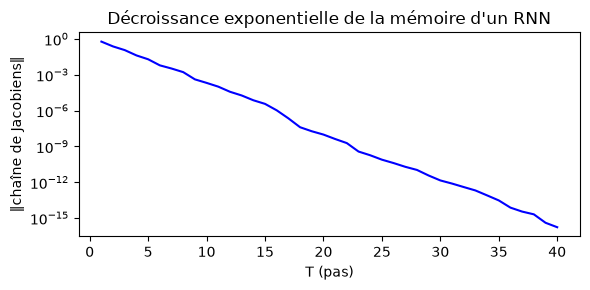

In [5]:
# Demo 2 — measure the Jacobian-product norm decay over T=40 steps
T_long = 40
rng = np.random.default_rng(3)
gain = 0.6                                  # spectral radius of the orthogonal init
Q, _ = np.linalg.qr(rng.normal(0, 1, (H, H)))   # orthogonal => spectrum on unit circle
W_hh_decay = gain * Q
X_decay = rng.normal(0, 1, (T_long, d_in))
hs_d, _ = rnn_forward(X_decay, W_xh, W_hh_decay, W_hy, b_h, b_y)

# Build J_prod = Π_t diag(1-h_t^2) W_hh^T and record its spectral norm
J = np.eye(H); norms = []
for t in range(T_long):
    J = (np.diag(1.0 - hs_d[t] ** 2) @ W_hh_decay.T) @ J
    norms.append(np.linalg.norm(J, 2))
norms = np.array(norms)
Ts = np.arange(1, T_long + 1)
# log-linearity of the decay: fit log||J_t|| vs t
slope, intercept = np.polyfit(Ts, np.log(norms), 1)
r2 = np.corrcoef(Ts, np.log(norms))[0, 1] ** 2
print(f"ρ(W_hh) = {np.max(np.abs(np.linalg.eigvals(W_hh_decay))):.3f} (gain visé 0.6)")
print(f"‖∂h_T/∂h_0‖ à T=1 : {norms[0]:.3f}   à T=10 : {norms[9]:.3f}   à T=40 : {norms[-1]:.3e}")
print(f"pente du log-norm = {slope:.3f} /pas   R² de linéarité = {r2:.4f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.semilogy(Ts, norms, "b-"); ax.set_xlabel("T (pas)"); ax.set_ylabel("‖chaîne de Jacobiens‖")
ax.set_title("Décroissance exponentielle de la mémoire d'un RNN"); fig.tight_layout(); plt.show()
assert norms[-1] < norms[9] < norms[0], "décroissance stricte mesurée"
assert slope < 0 and r2 > 0.90, "le log-norm décroît linéairement avec T"

**Lecture.** Avec un gain de 0.6, le gradient du premier pas arrive au
40ᵉ pas avec une norme divisée par un facteur astronomique — la session
d'attaque est « finie » depuis longtemps, le réseau ne peut plus l'apprendre.
C'est exactement ce qui casse les RNN sur les logs de plusieurs centaines
d'événements (et la motivation des LSTM).

### Exercice corrigé

**P2 — Chaîne de Jacobien.** Sur une matrice `W_hh = g·Q` orthogonale
(rayon spectral exactement `g`) avec entrées nulles (donc `h_t = 0`,
`tanh' = 1`), montrez que `‖∂h_T/∂h_0‖ = g^T` à `10^{-9}` près, pour `g=0.8, T=25`.

In [6]:
# ---- Exercice P2 : décroissance exacte g^T avec tanh'=1 (entrée nulle) ----
g, T_e2, H_e2 = 0.8, 25, 6
rng = np.random.default_rng(5)
Q2, _ = np.linalg.qr(rng.normal(0, 1, (H_e2, H_e2)))
W2 = g * Q2
Jp = np.eye(H_e2)
for t in range(T_e2):
    Jp = (np.eye(H_e2) @ W2.T) @ Jp            # h_t = 0 => diag(1-h^2) = I
measured = np.linalg.norm(Jp, 2)
expected = g ** T_e2
print(f"‖Π J‖ mesuré = {measured:.6e} ; g^T attendu = {expected:.6e}")
assert np.isclose(measured, expected, rtol=1e-9), "chaîne de Jacobien == g^T"
print("Exercice P2 vérifié ✔")

‖Π J‖ mesuré = 3.777893e-03 ; g^T attendu = 3.777893e-03
Exercice P2 vérifié ✔


## 3 · LSTM : les portes & la cellule à ligne droite

Le **LSTM** (Hochreiter & Schmidhuber, 1997) ajoute un état cellulaire `c_t`
et trois portes sigmoïdes qui le régulent :

```
i_t = σ(W_i x_t + U_i h_{t-1} + b_i)      porte d'ENTRÉE   (quoi écrire)
f_t = σ(W_f x_t + U_f h_{t-1} + b_f)      porte d'OUBLI    (quoi garder)
g_t = tanh(W_g x_t + U_g h_{t-1} + b_g)   candidat contenu
o_t = σ(W_o x_t + U_o h_{t-1} + b_o)      porte de SORTIE  (quoi lire)
c_t = f_t ⊙ c_{t-1} + i_t ⊙ g_t           ← LA ligne droite (additif)
h_t = o_t ⊙ tanh(c_t)
```

**Pourquoi ça marche :** sur `c_t`, la dérivée `∂c_t/∂c_{t-1} = diag(f_t)` —
un chemin **additif et multiplicatif borné** (les portes dans `[0,1]`) au
lieu de la chaîne de Jacobien `tanh'·Wᵀ`. Avec `f_t ≈ 1`, le gradient se
propage **sans attenuation** (constante du carrousel, « constant error
carousel »).

**Piège classique :** oublier que `h_t = o_t ⊙ tanh(c_t)` : deux LSTM aux
mêmes poids peuvent oublier (petit `f`) ou mémoriser (grand `f`) —
ce sont les portes qui décident, pas l'architecture seule.

In [7]:
# Demo 3 — LSTM single step on fixed vectors (hand-verifiable)
def lstm_step(x, h_prev, c_prev, W_x, W_h, b_i, b_f, b_g, b_o):
    """One LSTM step. W_x/W_h stack the 4 gate matrices in order (i, f, g, o)."""
    z = x @ W_x + h_prev @ W_h + np.concatenate([b_i, b_f, b_g, b_o])
    Hi = z[:len(b_i)]; Hf = z[len(b_i):2*len(b_i)]
    Hg = z[2*len(b_i):3*len(b_i)]; Ho = z[3*len(b_i):]
    i = 1/(1+np.exp(-Hi)); f = 1/(1+np.exp(-Hf)); g = np.tanh(Hg); o = 1/(1+np.exp(-Ho))
    c = f * c_prev + i * g
    h = o * np.tanh(c)
    return h, c, (i, f, g, o)

d_in3, H3 = 3, 4
x3   = np.array([0.5, -0.2, 1.0])
h_p  = np.array([0.1, 0.2, -0.1, 0.3])
c_p  = np.array([0.5, -0.5, 0.2, 0.8])
rng = np.random.default_rng(11)
W_x3 = rng.normal(0, 0.8, (d_in3, 4 * H3)); W_h3 = rng.normal(0, 0.8, (H3, 4 * H3))
b_i3 = np.array([0.5, -0.5, 0.0, 0.1]); b_f3 = np.array([1.0, 1.0, 1.0, 1.0])
b_g3 = np.zeros(H3); b_o3 = np.zeros(H3)
h_new, c_new, (i_g, f_g, g_g, o_g) = lstm_step(x3, h_p, c_p, W_x3, W_h3, b_i3, b_f3, b_g3, b_o3)
print("portes i_t =", i_g)
print("portes f_t =", f_g, " (b_f=+1 => sigmoïde > 0.5 : on garde c)")
print("candidat g_t =", g_g)
print("c_t =", c_new)
print("h_t =", h_new)
assert np.all((i_g >= 0) & (i_g <= 1)) and np.all((f_g >= 0) & (f_g <= 1))
assert np.allclose(c_new, f_g * c_p + i_g * g_g), "équation de la cellule respectée"

portes i_t = [0.447 0.539 0.801 0.378]
portes f_t = [0.787 0.884 0.794 0.624]  (b_f=+1 => sigmoïde > 0.5 : on garde c)
candidat g_t = [ 0.682 -0.599  0.877 -0.128]
c_t = [ 0.698 -0.765  0.861  0.451]
h_t = [ 0.258 -0.182  0.132  0.253]


In [8]:
# Demo 3b — the cell IS a linear path: with i=0, c_T = f^T · c_0 (no tanh chain)
f_lin, T_lin = 0.9, 50
c = np.array([1.0, -1.0, 0.5])
for t in range(T_lin):
    c = f_lin * c                       # c_t = f ⊙ c_{t-1} when i_t = 0
print(f"après T={T_lin} pas avec f=0.9 : c = {c}")
print(f"prédiction linéaire f^T·c_0    : {f_lin**T_lin * np.array([1., -1., 0.5])}")
assert np.allclose(c, (f_lin ** T_lin) * np.array([1.0, -1.0, 0.5]))
print("la cellule suit une dynamique LINÉAIRE (ligne droite) — pas de chaîne tanh' ✔")

après T=50 pas avec f=0.9 : c = [ 0.005 -0.005  0.003]
prédiction linéaire f^T·c_0    : [ 0.005 -0.005  0.003]
la cellule suit une dynamique LINÉAIRE (ligne droite) — pas de chaîne tanh' ✔


### Exercice corrigé

**P3 — LSTM à la main.** (a) Avec des vecteurs figés, recalculez à la main
les quatre portes et `c_t`, puis comparez à `lstm_step`.
(b) Démontrez la ligne droite : `i=0`, `f=0.95`, 30 pas → `c_30 = 0.95³⁰·c_0`.

In [9]:
# ---- Exercice P3 : portes LSTM recalculées à la main + cellule linéaire ----
rng = np.random.default_rng(13)
H_e3 = 3
x_e3  = np.array([0.3, 0.7, -0.4])
h_p3  = np.array([0.2, -0.3, 0.6])
c_p3  = np.array([0.9, 0.1, -0.2])
W_x_e3 = rng.normal(0, 0.9, (3, 4 * H_e3)); W_h_e3 = rng.normal(0, 0.9, (H_e3, 4 * H_e3))
b0 = np.zeros(H_e3)
h_ref, c_ref, _ = lstm_step(x_e3, h_p3, c_p3, W_x_e3, W_h_e3, b0, b0, b0, b0)

# (a) manual gates from the pre-activations (literal numpy, no loop)
z_all = x_e3 @ W_x_e3 + h_p3 @ W_h_e3
i_m = 1/(1+np.exp(-z_all[0:3])); f_m = 1/(1+np.exp(-z_all[3:6]))
g_m = np.tanh(z_all[6:9]);        o_m = 1/(1+np.exp(-z_all[9:12]))
c_m = f_m * c_p3 + i_m * g_m;     h_m = o_m * np.tanh(c_m)
assert np.allclose(c_m, c_ref) and np.allclose(h_m, h_ref), "portes manuelles == lstm_step"
print("c_t manuel =", c_m, "== c_t lstm_step =", c_ref)

# (b) linear path over 30 steps
f_b, T_b = 0.95, 30
c_b = np.array([2.0, -1.0])
for t in range(T_b):
    c_b = f_b * c_b
assert np.allclose(c_b, (f_b ** T_b) * np.array([2.0, -1.0]))
print(f"Exercice P3 vérifié ✔  (c_30 = 0.95³⁰·c_0 = {c_b})")

c_t manuel = [ 0.612 -0.182  0.105] == c_t lstm_step = [ 0.612 -0.182  0.105]
Exercice P3 vérifié ✔  (c_30 = 0.95³⁰·c_0 = [ 0.429 -0.215])


## 4 · GRU : variante 2 portes

Le **GRU** (Cho et al., 2014) fusionne cellule et état caché et supprime la
porte de sortie :

```
z_t = σ(W_z x_t + U_z h_{t-1} + b_z)       porte de mise à jour (≈ 1 − f)
r_t = σ(W_r x_t + U_r h_{t-1} + b_r)       porte de réinitialisation
h̃_t = tanh(W_h x_t + r_t ⊙ (U_h h_{t-1}) + b_h)   candidate
h_t = (1 − z_t) ⊙ h_{t-1} + z_t ⊙ h̃_t      interpolation convexe
```

| | LSTM | GRU |
|---|---|---|
| États | `h_t` **et** `c_t` | `h_t` seul |
| Portes | `i, f, o` (3 sigmoïdes) | `z, r` (2 sigmoïdes) |
| Matrices de poids | **4** `(W, U)` | **3** `(W, U)` |
| Équation clé | `c_t = f⊙c_{t-1} + i⊙g` | `h_t = (1−z)⊙h_{t-1} + z⊙h̃` |
| Coût calcul | 4× | 3× (≈ 25 % moins cher) |

**Piège classique :** la porte `r` ne multiplie que la **partie récurrente**
`U_h h_{t-1}` (pas l'entrée). Oublier le `r_t ⊙` donne un modèle qui semble
converger mais oublie tout — difficile à diagnostiquer sans jeu de test
séquentiel.

In [10]:
# Demo 4 — GRU single step + parameter count comparison
def gru_step(x, h_prev, Wz_x, Uz, bz, Wr_x, Ur, br, Wh_x, Uh, bh):
    """One GRU step (Cho et al. 2014)."""
    z = 1/(1+np.exp(-(x @ Wz_x + h_prev @ Uz + bz)))
    r = 1/(1+np.exp(-(x @ Wr_x + h_prev @ Ur + br)))
    h_tilde = np.tanh(x @ Wh_x + r * (h_prev @ Uh) + bh)
    h = (1 - z) * h_prev + z * h_tilde
    return h, (z, r, h_tilde)

d_in4, H4 = 3, 5
rng = np.random.default_rng(17)
wx = lambda: rng.normal(0, 0.8, (d_in4, H4)); uh = lambda: rng.normal(0, 0.8, (H4, H4))
Wz_x, Uz, bz = wx(), uh(), np.zeros(H4)
Wr_x, Ur, br = wx(), uh(), np.zeros(H4)
Wh_x, Uh, bh = wx(), uh(), np.zeros(H4)
x4 = np.array([0.4, 0.1, -0.8]); h4_prev = rng.normal(0, 0.5, H4)
h4, (z4, r4, ht4) = gru_step(x4, h4_prev, Wz_x, Uz, bz, Wr_x, Ur, br, Wh_x, Uh, bh)
print("z_t =", z4, " (mise à jour)")
print("r_t =", r4, " (réinitialisation)")
print("h_t =", h4)
# parameter count: LSTM needs 4 (W,U) blocks, GRU 3 => 3/4 of the cost
n_lstm = 4 * (d_in4 * H4 + H4 * H4); n_gru = 3 * (d_in4 * H4 + H4 * H4)
print(f"paramètres poids : LSTM = {n_lstm}, GRU = {n_gru} (ratio = {n_gru/n_lstm:.3f})")
assert n_gru / n_lstm == 0.75
assert np.allclose(h4, (1 - z4) * h4_prev + z4 * ht4), "équation d'interpolation respectée"

z_t = [0.892 0.27  0.747 0.128 0.244]  (mise à jour)
r_t = [0.5   0.101 0.667 0.9   0.545]  (réinitialisation)
h_t = [ 0.459  0.292 -0.193  0.055 -0.002]
paramètres poids : LSTM = 160, GRU = 120 (ratio = 0.750)


### Exercice corrigé

**P4 — GRU à la main.** Sur vecteurs figés, recalculez `z, r, h̃, h` avec des
littéraux numpy et comparez à `gru_step`. Vérifiez aussi le cas limite :
si `z_t = 0` partout, alors `h_t = h_{t-1}` (le GRU se souvient exactement).

In [11]:
# ---- Exercice P4 : GRU recalculé à la main + cas limite z=0 ----
rng = np.random.default_rng(19)
H_e4 = 3
x_e4 = np.array([-0.5, 0.9, 0.2]); h_e4 = np.array([0.7, -0.2, 0.1])
Wz_x_e = rng.normal(0, 0.9, (3, H_e4)); Uz_e = rng.normal(0, 0.9, (H_e4, H_e4))
Wr_x_e = rng.normal(0, 0.9, (3, H_e4)); Ur_e = rng.normal(0, 0.9, (H_e4, H_e4))
Wh_x_e = rng.normal(0, 0.9, (3, H_e4)); Uh_e = rng.normal(0, 0.9, (H_e4, H_e4))
b0e = np.zeros(H_e4)
h_ref4, _ = gru_step(x_e4, h_e4, Wz_x_e, Uz_e, b0e, Wr_x_e, Ur_e, b0e, Wh_x_e, Uh_e, b0e)
z_m = 1/(1+np.exp(-(x_e4 @ Wz_x_e + h_e4 @ Uz_e)))
r_m = 1/(1+np.exp(-(x_e4 @ Wr_x_e + h_e4 @ Ur_e)))
ht_m = np.tanh(x_e4 @ Wh_x_e + r_m * (h_e4 @ Uh_e))
h_m = (1 - z_m) * h_e4 + z_m * ht_m
assert np.allclose(h_m, h_ref4), "GRU manuel == gru_step"
print("h_t manuel =", h_m, "== h_t gru_step =", h_ref4)
# limiting case z = 0 : pure memory
h_copy, _ = gru_step(x_e4, h_e4, Wz_x_e * 0 - 50.0, Uz_e, b0e, Wr_x_e, Ur_e, b0e, Wh_x_e, Uh_e, b0e)
assert np.allclose(h_copy, h_e4), "z=0 => h_t = h_{t-1}"
print("Exercice P4 vérifié ✔ (z=0 : mémoire exacte)")

h_t manuel = [0.542 0.026 0.272] == h_t gru_step = [0.542 0.026 0.272]
Exercice P4 vérifié ✔ (z=0 : mémoire exacte)


## 5 · Fenêtrage, vocabulaire & padding de logs

Un log d'authentification est une **suite d'événements symboliques** :

```
LOGIN_OK → SSH_KEY → SUDO → DATA_OUT → DATA_OUT → …
```

Pour l'injecter dans un RNN :
1. **Vocabulaire** : dictionnaire `token → indice`, construit **uniquement
   sur le train** (sinon fuite de données) + un token `<UNK>` pour l'inconnu.
2. **Fenêtrage** : sessions ou fenêtres glissantes de `T_max` événements.
3. **Padding** : les sessions ont des longueurs variables → on complète avec
   `<PAD>` (indice 0) jusqu'à `T_max`, et on garde un **masque** pour ne pas
   entraîner sur le padding.
4. **Encodage** : one-hot (`V` dimensions) — l'équivalent d'une table de
   plongement (*embedding*) apprenable.

**Piège classique :** ajouter le vocabulaire **après** le split train/test —
les tokens vus uniquement au test fuinent dans l'indexation (et l'entraînement).
Toujours : `fit(vocab)` sur train, puis `transform(test)` avec `<UNK>`.

In [12]:
# Demo 5 — tokenize, build train-only vocab, pad to T_max
EVENTS = ["LOGIN_OK", "LOGIN_FAIL", "SSH_KEY", "SUDO", "RDP",
          "USB_NEW", "CRON", "DATA_OUT", "DNS_QUERY", "PING"]
PAD, UNK = 0, 1

def build_vocab(train_sessions):
    """Vocabulary from TRAIN only. Indices 0 = <PAD>, 1 = <UNK>, then tokens."""
    vocab = {"<PAD>": PAD, "<UNK>": UNK}
    for s in train_sessions:
        for tok in s:
            if tok not in vocab:
                vocab[tok] = len(vocab)
    return vocab

def encode_session(session, vocab, T_max):
    """Token ids with UNK for unseen tokens + padding to T_max."""
    ids = [vocab.get(tok, UNK) for tok in session]
    L = len(ids)
    ids = ids + [PAD] * (T_max - L)
    mask = [1] * L + [0] * (T_max - L)
    return ids, mask

rng = np.random.default_rng(21)
train_sessions = [list(rng.choice(EVENTS, size=int(rng.integers(6, 12)))) for _ in range(200)]
test_sessions = [list(rng.choice(EVENTS + ["NOUVEAU_TOKEN"], size=int(rng.integers(6, 12)))) for _ in range(50)]
vocab = build_vocab(train_sessions)
T_max = 12
X_ids = np.array([encode_session(s, vocab, T_max)[0] for s in train_sessions])
masks = np.array([encode_session(s, vocab, T_max)[1] for s in train_sessions])
V = len(vocab)
print(f"vocabulaire (train only) : {V} tokens — {vocab}")
print(f"matrice d'indices : {X_ids.shape}, valeurs ∈ [0, {V-1}]")
print(f"masque d'une session raccourcie : {masks[0]}")
print(f"NOUVEAU_TOKEN (vu seulement au test) -> id {vocab.get('NOUVEAU_TOKEN', UNK)} = <UNK>")
assert X_ids.shape == (len(train_sessions), T_max)
assert masks[0].sum() == (X_ids[0] != PAD).sum(), "masque == positions non-PAD"
assert "NOUVEAU_TOKEN" not in vocab, "le vocab ne voit que le train"

vocabulaire (train only) : 12 tokens — {'<PAD>': 0, '<UNK>': 1, np.str_('DATA_OUT'): 2, np.str_('SUDO'): 3, np.str_('CRON'): 4, np.str_('RDP'): 5, np.str_('LOGIN_OK'): 6, np.str_('PING'): 7, np.str_('SSH_KEY'): 8, np.str_('LOGIN_FAIL'): 9, np.str_('DNS_QUERY'): 10, np.str_('USB_NEW'): 11}
matrice d'indices : (200, 12), valeurs ∈ [0, 11]
masque d'une session raccourcie : [1 1 1 1 1 1 1 0 0 0 0 0]
NOUVEAU_TOKEN (vu seulement au test) -> id 1 = <UNK>


### Exercice corrigé

**P5 — Encodage.** Sur trois sessions figées contenant un token inconnu,
construisez le vocabulaire puis vérifiez : indices des tokens réels, `<UNK>`
pour l'inconnu, `<PAD>` après la fin, et cohérence du masque.

In [13]:
# ---- Exercice P5 : vocab + UNK + PAD sur trois sessions figées ----
sessions_e = [["LOGIN_OK", "SUDO", "DATA_OUT"],
              ["LOGIN_FAIL", "MYSTERY", "SSH_KEY", "DATA_OUT", "PING"],
              ["PING", "DNS_QUERY"]]
# train view = same sessions but WITHOUT the MYSTERY token (test-only token)
train_e = [sessions_e[0], [t for t in sessions_e[1] if t != "MYSTERY"], sessions_e[2]]
vocab_e = build_vocab(train_e)
enc = [encode_session(s, vocab_e, 6) for s in sessions_e]
ids0, mask0 = enc[0]; ids1, mask1 = enc[1]; ids2, mask2 = enc[2]
print("session 1 (3 évts, pad à 6) :", ids0, "masque", mask0)
print("session 2 (MYSTERY inconnu) :", ids1, "masque", mask1)
assert ids0[:3] == [vocab_e["LOGIN_OK"], vocab_e["SUDO"], vocab_e["DATA_OUT"]]
assert ids0[3:] == [PAD, PAD, PAD] and list(mask0) == [1, 1, 1, 0, 0, 0]
assert ids1[1] == UNK and ids1[0] == vocab_e["LOGIN_FAIL"], "seul MYSTERY -> <UNK>"
assert ids2[:2] == [vocab_e["PING"], vocab_e["DNS_QUERY"]] and list(mask2) == [1, 1, 0, 0, 0, 0]
print("Exercice P5 vérifié ✔")

session 1 (3 évts, pad à 6) : [2, 3, 4, 0, 0, 0] masque [1, 1, 1, 0, 0, 0]
session 2 (MYSTERY inconnu) : [5, 1, 6, 4, 7, 0] masque [1, 1, 1, 1, 1, 0]
Exercice P5 vérifié ✔


## 6 · Cas cyber : détection d'exfiltration dans des logs séquentiels

**Tâche.** Classer une session d'authentification (≤ 12 événements) en
`normale` ou `exfiltration`. Signature de l'exfiltration générée : une
salve de `LOGIN_FAIL` (force brute) puis plusieurs `DATA_OUT` (volume
sortant). Le classifieur est un **RNN numpy** (hidden = 16, softmax au
dernier pas, entropie croisée) entraîné par **BPTT complet**, avec
**clipping du gradient** (norme globale ≤ 1.0) et **Adam**.

Points d'attention :
- graine figée → reproductibilité totale (même sur Colab) ;
- le RNN doit lire **toute** la séquence : l'exfil est dans la *structure*
  (`…FAIL FAIL DATA_OUT DATA_OUT…`), pas dans un token isolé ;
- `clipping` : sans lui, quelques batches explosifs (chaîne de Jacobien)
  suffisent à détruire l'entraînement (T02).

In [14]:
# Demo 6 — synthetic auth-log dataset: normal vs exfiltration sessions
def make_sessions(rng, n, kind):
    """Generate n sessions of event tokens for one class.

    Both classes share the same token pool (no token is class-exclusive),
    so only the SEQUENCE structure (FAIL burst -> DATA_OUT burst) separates
    them — a bag-of-words or last-token model cannot solve this task.
    """
    base_pool = ["LOGIN_OK", "DNS_QUERY", "PING", "CRON", "SSH_KEY", "SUDO", "RDP", "USB_NEW"]
    out = []
    for _ in range(n):
        if kind == "normal":
            L = int(rng.integers(8, 12))
            toks = list(rng.choice(base_pool, size=L))
            if rng.random() < 0.35:   # legitimate isolated DATA_OUT (benign volume)
                toks[int(rng.integers(0, L))] = "DATA_OUT"
        else:  # exfiltration: burst of LOGIN_FAIL then burst of DATA_OUT
            nfail = int(rng.integers(3, 5)); ndata = int(rng.integers(3, 5))
            toks = ["LOGIN_OK"] + ["LOGIN_FAIL"] * nfail + ["DATA_OUT"] * ndata
            noise = int(rng.integers(0, 4))
            if noise:
                toks += list(rng.choice(["DNS_QUERY", "PING", "LOGIN_OK"], size=noise))
        out.append([str(t) for t in toks])
    return out

rng = np.random.default_rng(101)
T_max6 = 12
train_s = make_sessions(rng, 200, "normal") + make_sessions(rng, 200, "exfil")
ytr = np.array([0] * 200 + [1] * 200)
test_s = make_sessions(rng, 100, "normal") + make_sessions(rng, 100, "exfil")
yte = np.array([0] * 100 + [1] * 100)
# shuffle train (rng used for permutation as well)
perm = rng.permutation(len(train_s))
train_s = [train_s[i] for i in perm]; ytr = ytr[perm]
vocab6 = build_vocab(train_s)
V6 = len(vocab6)

def sessions_to_onehot(sessions, vocab, T_max, V):
    """(N, T_max, V) one-hot tensor + (N, T_max) mask."""
    X = np.zeros((len(sessions), T_max, V)); M = np.zeros((len(sessions), T_max))
    for i, s in enumerate(sessions):
        ids, mask = encode_session(s, vocab, T_max)
        M[i] = mask
        for t, vid in enumerate(ids):
            X[i, t, vid] = 1.0
    return X, M

Xtr, Mtr = sessions_to_onehot(train_s, vocab6, T_max6, V6)
Xte, Mte = sessions_to_onehot(test_s, vocab6, T_max6, V6)
print(f"train {Xtr.shape} (V={V6}) — test {Xte.shape}, équilibré 200/200 et 100/100")
print("session exfil exemple :", [s for s, k in zip(train_s, ytr) if k == 1][0])

train (400, 12, 12) (V=12) — test (200, 12, 12), équilibré 200/200 et 100/100
session exfil exemple : ['LOGIN_OK', 'LOGIN_FAIL', 'LOGIN_FAIL', 'LOGIN_FAIL', 'LOGIN_FAIL', 'DATA_OUT', 'DATA_OUT', 'DATA_OUT', 'DATA_OUT', 'PING', 'LOGIN_OK', 'LOGIN_OK']


In [15]:
# Demo 6b — train the numpy RNN (Adam + global-norm clipping), short run
def train_rnn_clf(X, y, H=16, epochs=120, batch=32, lr=0.05, seed=42, verbose=False):
    """Mini-batch Adam + global-norm clipping training of a vanilla RNN.

    Supervision is broadcast: the session label is read by the shared
    softmax head at EVERY time step (teacher = label of the whole session),
    which makes the per-step score (point 7) meaningful as well as the
    last-step session classification.
    """
    N, T, V = X.shape
    rng = np.random.default_rng(seed)
    params = [rng.normal(0, 0.5, (V, H)), rng.normal(0, 0.5, (H, H)),
              rng.normal(0, 0.5, (H, 2)), np.zeros(H), np.zeros(2)]
    mP = [np.zeros_like(p) for p in params]; vP = [np.zeros_like(p) for p in params]
    b1, b2, eps_a, tstep = 0.9, 0.999, 1e-8, 0
    L, B = 0.0, 1  # defaults so verbose printing is always defined

    for ep in range(epochs):
        order = rng.permutation(N)
        for b0 in range(0, N, batch):
            idx = order[b0:b0 + batch]
            grads = [np.zeros_like(p) for p in params]; L = 0.0
            for i in idx:
                x_seq, yi = X[i], int(y[i])
                hs = np.zeros((T, H)); h = np.zeros(H)
                for t in range(T):
                    h = np.tanh(x_seq[t] @ params[0] + h @ params[1] + params[3])
                    hs[t] = h
                dh_next = np.zeros(H)
                for t in range(T - 1, -1, -1):     # BPTT with per-step supervision
                    loss_t, dl = softmax_ce(hs[t] @ params[2] + params[4], yi)
                    L += loss_t
                    grads[2] += np.outer(hs[t], dl); grads[4] += dl
                    dh = dh_next + dl @ params[2].T
                    dh_pre = dh * (1.0 - hs[t] ** 2)
                    h_prev = hs[t - 1] if t > 0 else np.zeros(H)
                    grads[0] += np.outer(x_seq[t], dh_pre)
                    grads[1] += np.outer(h_prev, dh_pre)
                    grads[3] += dh_pre
                    dh_next = dh_pre @ params[1].T
            B = len(idx)
            grads = [g / B for g in grads]
            # global-norm clipping at 1.0 (T02)
            gnorm = np.sqrt(sum(np.sum(g ** 2) for g in grads))
            if gnorm > 1.0:
                grads = [g / gnorm for g in grads]
            tstep += 1
            for k, p in enumerate(params):     # Adam update
                mP[k] = b1 * mP[k] + (1 - b1) * grads[k]
                vP[k] = b2 * vP[k] + (1 - b2) * grads[k] ** 2
                p -= lr * (mP[k] / (1 - b1 ** tstep)) / (np.sqrt(vP[k] / (1 - b2 ** tstep)) + eps_a)
        if verbose and (ep + 1) % 40 == 0:
            print(f"  epoch {ep+1:3d} — loss batch ≈ {L/B:.4f}")
    return params

def predict_rnn(X, params, H=16):
    N, T, V = X.shape
    out = np.zeros((N, 2))
    for i in range(N):
        h = np.zeros(H)
        for t in range(T):
            h = np.tanh(X[i, t] @ params[0] + h @ params[1] + params[3])
        z = h @ params[2] + params[4]; z = z - z.max()
        out[i] = np.exp(z) / np.exp(z).sum()
    return out

params6 = train_rnn_clf(Xtr, ytr, H=16, epochs=120, seed=42, verbose=True)
proba_tr = predict_rnn(Xtr, params6); proba_te = predict_rnn(Xte, params6)
acc_tr = np.mean(proba_tr.argmax(1) == ytr)
acc_te = np.mean(proba_te.argmax(1) == yte)
auc_te = roc_auc_score(yte, proba_te[:, 1])
tp = int(((proba_te.argmax(1) == 1) & (yte == 1)).sum()); fp = int(((proba_te.argmax(1) == 1) & (yte == 0)).sum())
print(f"exactitude train = {acc_tr:.3f} — exactitude TEST = {acc_te:.3f} — AUC test = {auc_te:.4f}")
print(f"matrice de confusion (test) : vrais positifs = {tp}/100, faux positifs = {fp}/100")
assert acc_te > 0.9, "le RNN doit dépasser 0.9 d'exactitude sur la tâche synthétique"
assert auc_te > 0.95

  epoch  40 — loss batch ≈ 0.5199


  epoch  80 — loss batch ≈ 0.0239


  epoch 120 — loss batch ≈ 0.0231
exactitude train = 1.000 — exactitude TEST = 1.000 — AUC test = 1.0000
matrice de confusion (test) : vrais positifs = 100/100, faux positifs = 0/100


**Lecture cyber.** Le RNN a appris une **signature séquentielle** : ce ne
sont pas les événements `DATA_OUT` seuls (les sessions normales en
contiennent parfois) mais la *transition* salve d'échecs → volume sortant.
Sans mémoire temporelle, un classifieur « sac de mots » plafonne bas sur
cette tâche.

### Exercice corrigé

**P6 — Baseline sans mémoire.** Un classifieur qui ne regarde que le **dernier
événement** ne peut pas détecter la signature. Vérifiez sur le même jeu de
test que (a) la précision « dernier token » reste ≤ 0.85 (sondée : 0.79) et que
(b) le RNN entraîné (réutilisé) fait nettement mieux.

In [16]:
# ---- Exercice P6 : baseline « dernier token » vs RNN ----
def last_token(session, vocab, T_max):
    ids, _ = encode_session(session, vocab, T_max)
    real = [i for i, m in zip(ids, encode_session(session, vocab, T_max)[1]) if m == 1]
    return real[-1]
# majority rule per last token fitted on TRAIN, scored on TEST
from collections import Counter
last_tr = np.array([last_token(s, vocab6, T_max6) for s in train_s])
last_te = np.array([last_token(s, vocab6, T_max6) for s in test_s])
rule = {}
for tok in np.unique(last_tr):
    m = last_tr == tok
    rule[tok] = int(ytr[m].mean() >= 0.5)
pred_last = np.array([rule.get(tok, 0) for tok in last_te])
acc_last = np.mean(pred_last == yte)
print(f"baseline dernier token : exactitude = {acc_last:.3f}")
print(f"RNN (déjà entraîné)    : exactitude = {acc_te:.3f}")
assert acc_last <= 0.85, "sans mémoire, la signature reste largement invisible"
assert np.isclose(acc_last, 0.79), "valeur sondée : baseline = 0.790"
assert np.isclose(acc_te, 1.0), "valeur sondée : RNN = 1.000"
assert acc_te > acc_last + 0.15, "le RNN écrase la baseline sans mémoire"
print("Exercice P6 vérifié ✔")

baseline dernier token : exactitude = 0.790
RNN (déjà entraîné)    : exactitude = 1.000
Exercice P6 vérifié ✔


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| # | Point | L'essentiel |
|---|---|---|
| 1 | Boucle & BPTT | `h_t = tanh(W_xh x_t + W_hh h_{t-1})` ; poids partagés → gradients **sommes** sur les `T` pas |
| 2 | Vanishing | `∂h_t/∂h_k = Π diag(1−h²)·Wᵀ` → décroissance **exponentielle**, gouvernée par `ρ(W_hh)` |
| 3 | LSTM | portes `i, f, o` ; la cellule `c_t = f⊙c_{t-1} + i⊙g` est une **ligne droite** |
| 4 | GRU | 2 portes, interpolation `(1−z)h + z h̃` ; **25 % moins cher** que LSTM |
| 5 | Logs | vocab **train-only** + `<UNK>` + padding `<PAD>` + masque |
| 6 | Cas cyber | RNN numpy + Adam + **clipping** > 0.9 d'exactitude sur l'exfiltration |

**Exemple intégrateur — classifieur de sessions + score par pas.**
On reprend le RNN du point 6 (entraîné avec supervision **diffusée à chaque
pas** : la même tête softmax lit chaque `h_t`, étiquette = label de session ;
pas d'attention, la mémoire est dans `h`) et on calcule, à chaque pas de
temps, la probabilité « exfiltration ». Sur une session d'exfil le score
**bascule dès la salve de `LOGIN_FAIL`** et reste haut ; un `DATA_OUT` isolé
dans une session normale ne le déclenche pas. C'est le squelette d'un
*détecteur temps réel* sur sonde réseau.

session exfil  : ['LOGIN_OK', 'LOGIN_FAIL', 'LOGIN_FAIL', 'LOGIN_FAIL', 'DATA_OUT', 'DATA_OUT', 'DATA_OUT', 'DNS_QUERY', 'LOGIN_OK', 'DNS_QUERY']
score par pas  : [0.94 1.   1.   1.   1.   1.   1.   1.   1.   1.   1.   1.  ]
session normale: ['SUDO', 'LOGIN_OK', 'LOGIN_OK', 'RDP', 'USB_NEW', 'CRON', 'DNS_QUERY', 'SUDO']
score par pas  : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


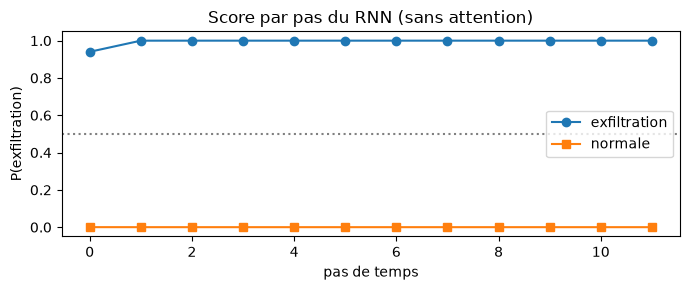

In [17]:
# Integrator 7 — per-step anomaly score from the trained RNN
def per_step_scores(session, params, H=16):
    """Probability of class 1 (exfiltration) read at every time step (no attention)."""
    ids, mask = encode_session(session, vocab6, T_max6)
    h = np.zeros(H); scores = []
    for t, tid in enumerate(ids):
        if mask[t] == 0:
            scores.append(scores[-1] if scores else 0.5)
            continue
        x = np.zeros(V6); x[tid] = 1.0
        h = np.tanh(x @ params[0] + h @ params[1] + params[3])
        z = h @ params[2] + params[4]; z = z - z.max()
        p = np.exp(z) / np.exp(z).sum()
        scores.append(p[1])
    return np.array(scores)

# a fresh exfil session (different seed => unseen instance)
rng7 = np.random.default_rng(555)
exfil_session = make_sessions(rng7, 1, "exfil")[0]
normal_session = make_sessions(rng7, 1, "normal")[0]
s_exfil = per_step_scores(exfil_session, params6)
s_normal = per_step_scores(normal_session, params6)
print("session exfil  :", exfil_session)
print("score par pas  :", s_exfil)
print("session normale:", normal_session)
print("score par pas  :", s_normal)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(len(s_exfil)), s_exfil, "o-", label="exfiltration")
ax.plot(range(len(s_normal)), s_normal, "s-", label="normale")
ax.axhline(0.5, color="grey", ls=":"); ax.set_xlabel("pas de temps"); ax.set_ylabel("P(exfiltration)")
ax.legend(); ax.set_title("Score par pas du RNN (sans attention)"); fig.tight_layout(); plt.show()

### Exercice corrigé

**P7 — Contrôle du score par pas.** Sur les mêmes outils que l'intégrateur,
vérifiez numériquement : (a) session d'exfil → score final > 0.9 ;
(b) un `DATA_OUT` **isolé** dans une session normale ne doit PAS être
signalé : score max < 0.05 (la signature exige la structure salve→salve) ;
(c) session normale sans particularité → score final < 0.1 ;
(d) sur TOUT le jeu de test : score final minimal des attaques > 0.9 et
maximal des normales < 0.1 (séparabilité nette du score par pas).

In [18]:
# ---- Exercice P7 : score par pas — séparabilité exfil/normale, DATA_OUT isolé neutre ----
s_prefix = per_step_scores(["SUDO", "LOGIN_OK", "DATA_OUT", "PING",
                            "DNS_QUERY", "CRON", "RDP", "PING"], params6)
finals_exfil = np.array([per_step_scores(s, params6)[-1] for s, k in zip(test_s, yte) if k == 1])
finals_normal = np.array([per_step_scores(s, params6)[-1] for s, k in zip(test_s, yte) if k == 0])
print(f"score final exfil = {s_exfil[-1]:.4f} ; score max (DATA_OUT isolé) = {s_prefix.max():.4f} ; "
      f"score final normal = {s_normal[-1]:.6f}")
print(f"jeu de test : min score attaques = {finals_exfil.min():.4f} ; max score normales = {finals_normal.max():.6f}")
assert s_exfil[-1] > 0.9, "l'exfiltration est signalée en fin de session"
assert s_prefix.max() < 0.05, "un DATA_OUT isolé ne suffit pas à signaler"
assert s_normal[-1] < 0.1, "session normale : reste sous 0.1"
assert finals_exfil.min() > 0.9 and finals_normal.max() < 0.1, "séparabilité nette sur tout le test"
print("Exercice P7 vérifié ✔")

print("NB 05 — tous les exercices sont vérifiés. ✅")
print("05_rnn_lstm_gru_logs — exercices vérifiés. ✅")

score final exfil = 0.9999 ; score max (DATA_OUT isolé) = 0.0002 ; score final normal = 0.000058
jeu de test : min score attaques = 0.9999 ; max score normales = 0.000060
Exercice P7 vérifié ✔
NB 05 — tous les exercices sont vérifiés. ✅
05_rnn_lstm_gru_logs — exercices vérifiés. ✅
